# ChurnShield AI — Explainable Customer Retention & Revenue Intelligence Platform

 # Exploratory Data Analysis

## 1) IMPORT LIBRAIES

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Set graph style
sns.set_style("whitegrid")

from scipy.stats import chi2_contingency

# Show all columns
pd.set_option("display.max_columns", None)

## 2) LOAD DATASET

In [41]:
df = pd.read_csv("Telco-Customer-Churn.csv")

In [42]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [43]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [44]:
df.shape # check dataset rows and columns

(7043, 21)

In [45]:
df.info() # check column names and data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 3) Checking Missing Values

In [46]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [47]:
df.duplicated().sum() # check duplicate rows

np.int64(0)

In [48]:
df["customerID"].duplicated().sum() # check duplicate customer IDs

np.int64(0)

## 4) Data Cleaning

##### Convert TotalCharges into numeric format

In [49]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [50]:
df["TotalCharges"]

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

#### check rows with missing TotalCharges

In [51]:
print("Missing TotalCharges:")
df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges"]]

Missing TotalCharges:


,tenure,MonthlyCharges
488,0,52.55
753,0,20.25
936,0,80.85
1082,0,25.75
1340,0,56.05
3331,0,19.85
3826,0,25.35
4380,0,20.00
5218,0,19.70
6670,0,73.35


#### Replace missing TotalCharges with 0
#### These customers have zero tenure

In [52]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [53]:
# Analyze zero-tenure customers

zero_tenure = df[df["tenure"] == 0]

print("Zero Tenure Customers:", len(zero_tenure))

print("\nChurn Distribution:")
print(zero_tenure["Churn"].value_counts())

print("\nCustomer Details:")
display(
    zero_tenure[
        ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

Zero Tenure Customers: 11

Churn Distribution:
Churn
No    11
Name: count, dtype: int64

Customer Details:


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


###  Remove customerID column

In [54]:
df = df.drop("customerID", axis=1)

In [55]:
print("shape after cleaning:", df.shape)

shape after cleaning: (7043, 20)


In [56]:
# Check duplicate rows after removing customerID

duplicate_count = df.duplicated().sum()

print("Duplicate Rows:", duplicate_count)

Duplicate Rows: 22


#### After removing the customerID column, 22 identical feature records were identified. These records may represent different customers with identical characteristics. Therefore, they were retained to preserve the original customer data.

# 5) FEATURE ENGINEERING 

##### Convert SeniorCitizen values into Yes and No

In [57]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({
    0: "No",
    1: "Yes"
})

In [58]:
df["SeniorCitizen"].head()

0    No
1    No
2    No
3    No
4    No
Name: SeniorCitizen, dtype: object

##### Convert Churn into numerical values
##### Yes = 1, No = 0

In [59]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

In [60]:
df["ChurnFlag"].head()

0    0
1    0
2    1
3    0
4    1
Name: ChurnFlag, dtype: int64

### Create tenure groups

In [61]:
df["tenure_group"] = pd.cut(df["tenure"],bins=[-1, 12, 24, 48, 72],
   labels=["0-12", "13-24", "25-48", "49-72"])

In [62]:
df["tenure_group"].head()

0     0-12
1    25-48
2     0-12
3    25-48
4     0-12
Name: tenure_group, dtype: category
Categories (4, object): ['0-12' < '13-24' < '25-48' < '49-72']

In [63]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag,tenure_group
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,25-48
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0-12


# 6) STATISTICAL SUMMARY

#### Basic statistical inforamation

In [64]:
print ("Statistical Summary:")
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

Statistical Summary:


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


#### Check skewness

In [65]:
print("Skewness:")
df[["tenure", "MonthlyCharges", "TotalCharges"]].skew().round(2)

Skewness:


tenure            0.24
MonthlyCharges   -0.22
TotalCharges      0.96
dtype: float64

# 7) OUTLIER DETECTION

In [66]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(col, "Outliers:", len(outliers))

tenure Outliers: 0
MonthlyCharges Outliers: 0
TotalCharges Outliers: 0


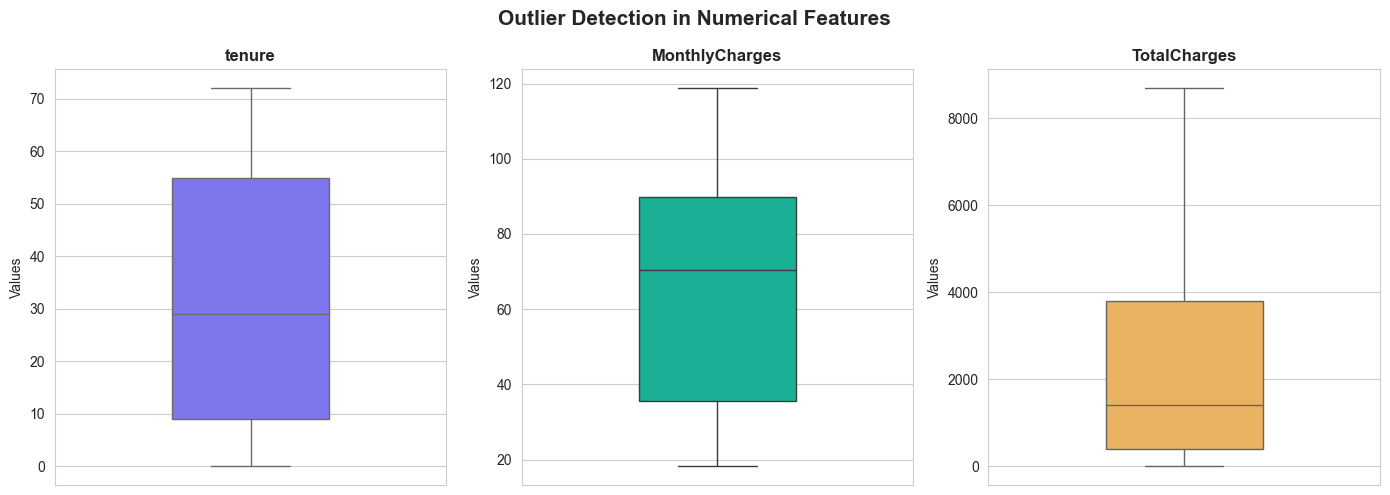

In [67]:

# Box Plot - Individual Numerical Features

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

colors = ["#6C63FF", "#00C9A7", "#FFB84D"]

for ax, col, color in zip(axes, num_cols, colors):

    sns.boxplot(y=df[col],ax=ax,color=color,width=0.4)
    ax.set_title(col, fontweight="bold")
    ax.set_ylabel("Values")

plt.suptitle(
    "Outlier Detection in Numerical Features",fontsize=15,fontweight="bold")
plt.tight_layout()
plt.show()


### # Numerical Feature Distributions

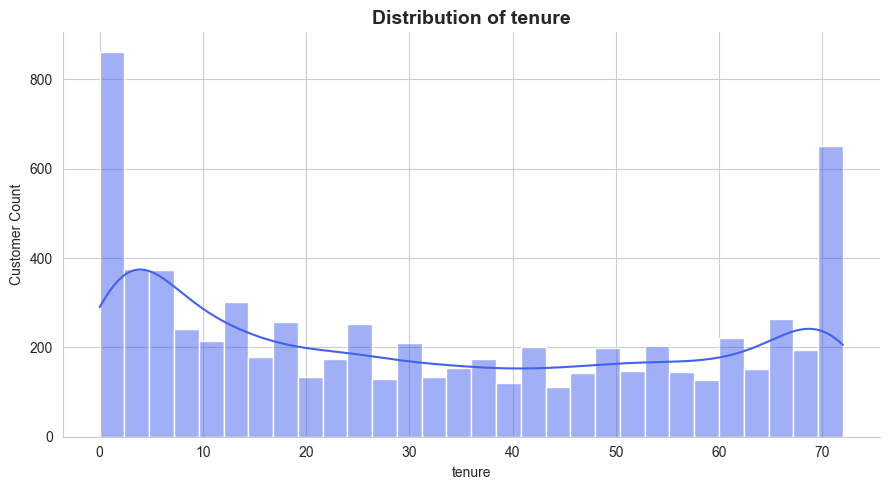

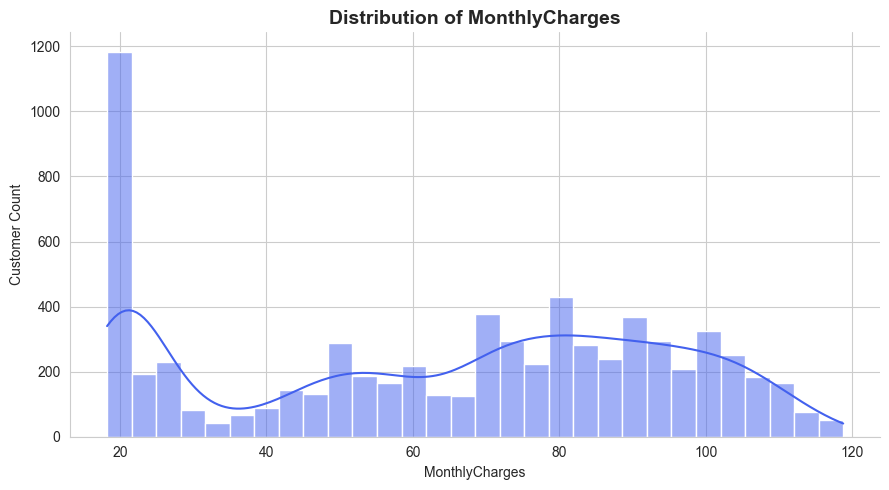

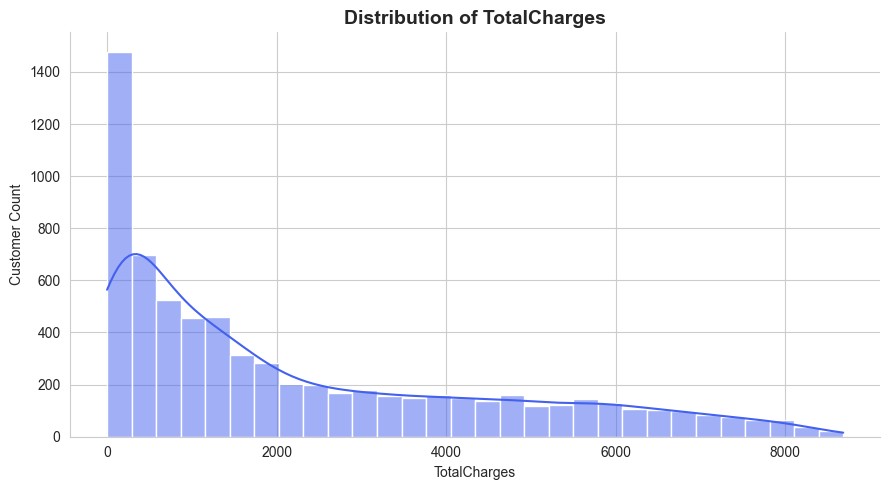

In [68]:
num_cols = ["tenure","MonthlyCharges","TotalCharges"]
for col in num_cols:
    plt.figure(figsize=(9, 5))
    sns.histplot(data=df,x=col,kde=True,color="#4361EE",bins=30)
    plt.title(f"Distribution of {col}",fontsize=14,fontweight="bold")

    plt.xlabel(col)
    plt.ylabel("Customer Count")

    sns.despine()
    plt.tight_layout()
    plt.show()

# 8) TARGET DISTRIBUTION

#### Count customers who left and stayed

In [69]:
print("Churn Distribution:")
df["Churn"].value_counts()

Churn Distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

### Calculate churn percentage

In [70]:
churn_rate = df["ChurnFlag"].mean() * 100

In [71]:
print("Churn Rate:", round(churn_rate, 2), "%")

Churn Rate: 26.54 %


### Visualize churn distribution

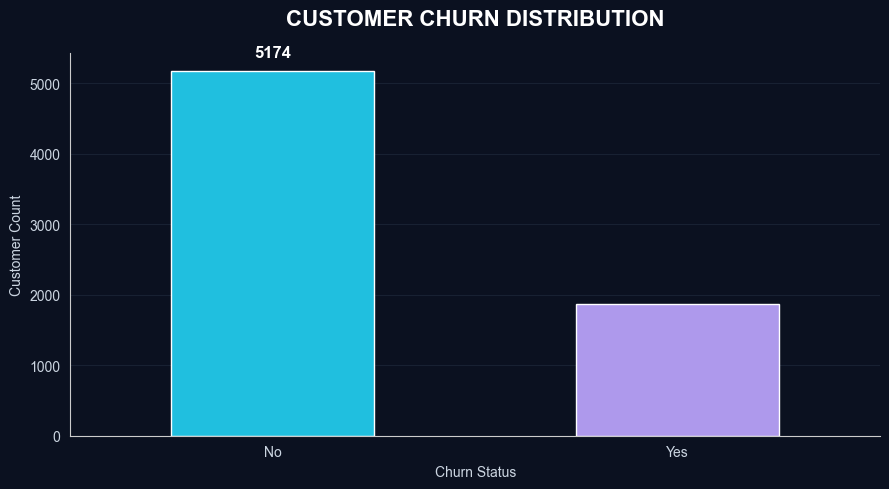

In [72]:

plt.figure(figsize=(9, 5), facecolor="#0B1120")

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette={"No": "#00D4FF", "Yes": "#A78BFA"},
    legend=False,
    width=0.5
)

ax.set_facecolor("#0B1120")

ax.bar_label(
    ax.containers[0],
    fmt="%d",
    padding=8,
    color="white",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    "CUSTOMER CHURN DISTRIBUTION",
    color="white",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Churn Status", color="#CBD5E1")
ax.set_ylabel("Customer Count", color="#CBD5E1")

ax.tick_params(colors="#CBD5E1")
ax.grid(axis="y", color="#334155", alpha=0.35)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()


# 9) CATEGORICAL FEATURES VS CHURN

In [73]:
cat_cols = df.select_dtypes(include="object").columns.drop("Churn")

In [74]:
print("Categorical Columns:")
print(cat_cols)

Categorical Columns:
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='object')


####  Check churn percentage for important features

In [75]:
features = ["Contract","InternetService","PaymentMethod","SeniorCitizen","Partner","TechSupport","OnlineSecurity"]

In [76]:
for col in features:
    churn_percentage = (df.groupby(col)["ChurnFlag"].mean() * 100)

    print("\nChurn Rate by", col)
    print(churn_percentage.round(2))


Churn Rate by Contract
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: ChurnFlag, dtype: float64

Churn Rate by InternetService
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: ChurnFlag, dtype: float64

Churn Rate by PaymentMethod
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: ChurnFlag, dtype: float64

Churn Rate by SeniorCitizen
SeniorCitizen
No     23.61
Yes    41.68
Name: ChurnFlag, dtype: float64

Churn Rate by Partner
Partner
No     32.96
Yes    19.66
Name: ChurnFlag, dtype: float64

Churn Rate by TechSupport
TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: ChurnFlag, dtype: float64

Churn Rate by OnlineSecurity
OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: ChurnFlag, dtype: fl

# 10) Chi-Square Test and Cramer's V

In [77]:
# Chi-Square Test and Cramer's V

chi_results = []
for col in cat_cols:

    table = pd.crosstab(df[col], df["Churn"])
    chi2, p_value, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()
    r, k = table.shape

    cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))
    chi_results.append({"Feature": col,"Chi2": chi2,"P-Value": p_value,"Cramers_V": cramers_v})
# Convert results into DataFrame
chi_results_df = pd.DataFrame(chi_results)
# Sort by effect size
chi_results_df = chi_results_df.sort_values(by="Cramers_V",ascending=False)

display(chi_results_df.round(4))

,Feature,Chi2,P-Value,Cramers_V
13,Contract,1184.5966,0.0000,0.4101
7,OnlineSecurity,849.9990,0.0000,0.3474
10,TechSupport,828.1971,0.0000,0.3429
6,InternetService,732.3096,0.0000,0.3225
15,PaymentMethod,648.1423,0.0000,0.3034
8,OnlineBackup,601.8128,0.0000,0.2923
9,DeviceProtection,558.4194,0.0000,0.2816
12,StreamingMovies,375.6615,0.0000,0.2310
11,StreamingTV,374.2039,0.0000,0.2305
14,PaperlessBilling,258.2776,0.0000,0.1915


# 11. SERVICES VS CHURN

In [78]:
services = ["OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]
service_data = {}

In [79]:
services

['OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies']

In [80]:
for col in services:
    rate = (df[df[col].isin(["Yes", "No"])].groupby(col)["ChurnFlag"].mean() * 100)  # Calculate churn rate for Yes and No
    service_data[col] = rate

In [81]:
# Convert results into DataFrame
service_df = pd.DataFrame(service_data).T
print(service_df.round(2))

                     No    Yes
OnlineSecurity    41.77  14.61
OnlineBackup      39.93  21.53
DeviceProtection  39.13  22.50
TechSupport       41.64  15.17
StreamingTV       33.52  30.07
StreamingMovies   33.68  29.94


### Create heatmap

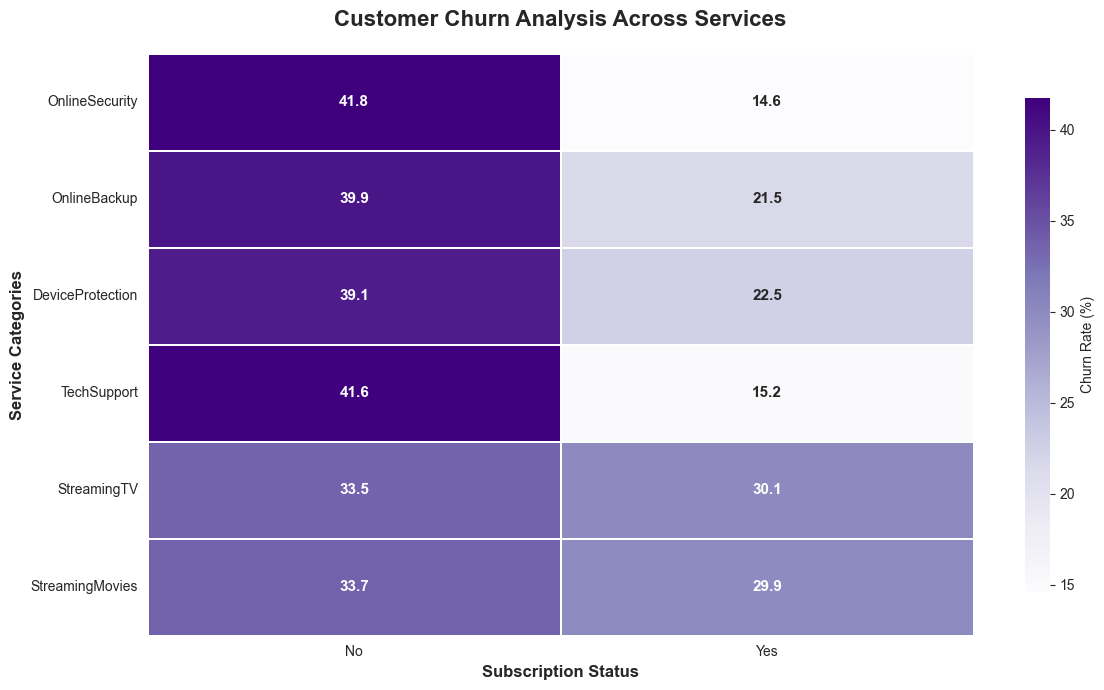

In [82]:

# Premium Churn Rate Heatmap

plt.figure(figsize=(12, 7))

sns.heatmap(service_df,annot=True,fmt=".1f",cmap="Purples",linewidths=1.2,linecolor="white",annot_kws={"size": 11, "weight": "bold"},
    cbar_kws={
        "label": "Churn Rate (%)",
        "shrink": 0.85
    }
)

plt.title(
    "Customer Churn Analysis Across Services",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Subscription Status", fontsize=12, fontweight="bold")
plt.ylabel("Service Categories", fontsize=12, fontweight="bold")

plt.xticks(rotation=0, fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()


#### Note: Customers with "No internet service" or "No phone service" are excluded from the Yes/No service comparison. Only customers with applicable service options are included.

# 12. REVENUE ANALYSIS

##### Calculate total monthly charges

In [83]:
total_revenue = df["MonthlyCharges"].sum()

In [84]:
total_revenue

np.float64(456116.6)

#### Calculate monthly charges of churned customers

In [85]:
churned_revenue = df[df["ChurnFlag"] == 1]["MonthlyCharges"].sum()

In [86]:
churned_revenue

np.float64(139130.85)

#### Calculate percentage

In [87]:
revenue_percentage = (churned_revenue / total_revenue) * 100

In [88]:
revenue_percentage

np.float64(30.503351555282137)

In [89]:
# Calculate annualised estimate
annual_revenue = churned_revenue * 12

print("Total Monthly Charges:", round(total_revenue, 2))

print("Monthly Charges of Churned Customers:",round(churned_revenue, 2))

print("Percentage:", round(revenue_percentage, 2), "%")

print("Estimated Annualized Revenue Associated with Churned Customers:",round(annual_revenue, 2))

Total Monthly Charges: 456116.6
Monthly Charges of Churned Customers: 139130.85
Percentage: 30.5 %
Estimated Annualized Revenue Associated with Churned Customers: 1669570.2


 # 13. REVENUE ANALYSIS BY CONTRACT

#### Total monthly charges by contract

In [90]:
total_contract_revenue = (df.groupby("Contract")["MonthlyCharges"].sum())

#### Monthly charges associated with churned customers

In [91]:
churn_contract_revenue = (df[df["ChurnFlag"] == 1].groupby("Contract")["MonthlyCharges"]
    .sum())

#### Calculate percentage

In [92]:
contract_percentage = (churn_contract_revenue / total_contract_revenue) * 100

In [93]:
print("Share of Monthly Charges Associated with Churned Customers by Contract (%):")
print(contract_percentage.round(2))

Share of Monthly Charges Associated with Churned Customers by Contract (%):
Contract
Month-to-month    46.97
One year          14.73
Two year           4.04
Name: MonthlyCharges, dtype: float64


# 14. CORRELATION ANALYSIS

#### Select numerical columns

In [94]:
numeric_data = df[["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]]

##### Calculate correlation

In [95]:
correlation = numeric_data.corr()
correlation.round(2)

,tenure,MonthlyCharges,TotalCharges,ChurnFlag
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
ChurnFlag,-0.35,0.19,-0.20,1.00


### Visualize correlation

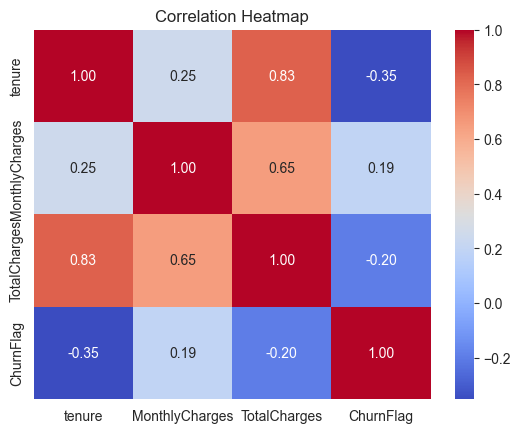

In [96]:
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()


##### Multicollinearity Observation

Tenure and TotalCharges show a strong positive correlation of approximately 0.83. This indicates overlapping information between these features.

During model development, this relationship should be considered, particularly when interpreting Logistic Regression coefficients and SHAP feature attributions.

### 15. CHURN RATE BY TENURE GROUP

In [97]:
tenure_churn = (df.groupby("tenure_group", observed=False)["ChurnFlag"].mean() * 100)
print("Churn Rate by Tenure Group:")
print(tenure_churn.round(2))

Churn Rate by Tenure Group:
tenure_group
0-12     47.44
13-24    28.71
25-48    20.39
49-72     9.51
Name: ChurnFlag, dtype: float64


### Create bar chart

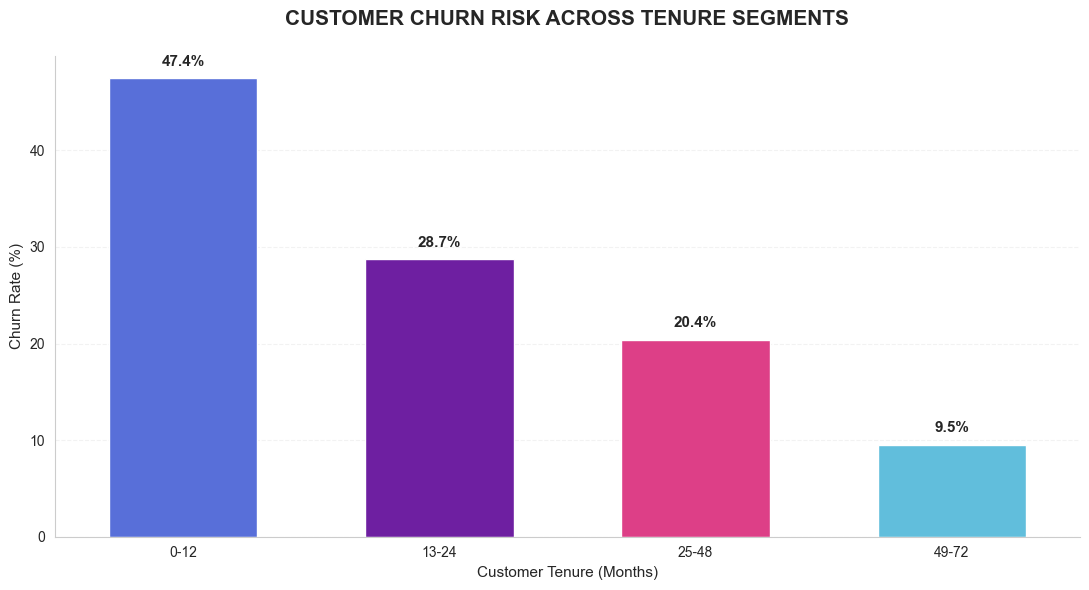

In [98]:
plt.figure(figsize=(11, 6))
colors = ["#4361EE", "#7209B7", "#F72585", "#4CC9F0"]

ax = sns.barplot(x=tenure_churn.index.astype(str),y=tenure_churn.values,hue=tenure_churn.index.astype(str),palette=colors,legend=False,width=0.58)

for container in ax.containers:
    ax.bar_label(container,fmt="%.1f%%",padding=7,fontsize=11,fontweight="bold")

ax.set_title(
    "CUSTOMER CHURN RISK ACROSS TENURE SEGMENTS",fontsize=15,fontweight="bold",pad=22)

ax.set_xlabel("Customer Tenure (Months)", fontsize=11)
ax.set_ylabel("Churn Rate (%)", fontsize=11)

ax.grid(axis="y", linestyle="--", alpha=0.25)

sns.despine()
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# 16. SAVE CLEANED DATASET

#### Remove EDA-only columns

In [99]:
cleaned_df = df.drop(columns=["ChurnFlag", "tenure_group"])

In [100]:
cleaned_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### save cleaned dataset

In [101]:
cleaned_df.to_csv("telco_cleaned.csv",index=False)

In [102]:
print("Cleaned Dataset Saved Successfully!")
print("Final Dataset Shape:", cleaned_df.shape)

Cleaned Dataset Saved Successfully!
Final Dataset Shape: (7043, 20)
